# Land DA scorecard: atmospheric forcing and surface response over land

Same verification window, experiments, scores and heat-map layout as the atmospheric scorecard (`analysis_atm_eval/04`–`05`), but scored **over land only** (land fraction ≥ 0.5, 60°S–90°N; Antarctica excluded so the ice sheet does not dominate):

* S0, 16–31 Dec 2011, 64 assimilation cycles; DART10/20/40 vs CTRL10 (no DA), % change in RMSE of the ensemble mean, paired block bootstrap (1-day blocks).
* **A Land surface state**: TS (skin temperature) and TREFHT, 6-hourly analyses vs ERA5.
* **B Surface radiation**: FSNS (net shortwave, i.e. albedo/snow), daily means of the 6-h forecasts vs ERA5 (00/06/12/18Z mean). Turbulent fluxes (LHFLX, SHFLX) are the land's response rather than forcing and are not shown.
* **C Forcing** from the atmosphere: PRECT (GPCP, IMERG, ERA5), FSDS, FLDS.

Soil moisture and snow cannot be scored over the window: the CTRL10/DART10 ELM history output does not contain them, and ERA5 6-hourly provides neither. FLNS is omitted because the ERA5 FLNS file is mostly zeros.

## 1. Settings

In [1]:
from pathlib import Path

INPUT_DATA_ROOT = Path("/compyfs/zhan391/v3_dart_cda_scratch")
OBSERVATION_ROOT = Path("/compyfs/zhan391/acme_init/Observations")   # observations (shared archive)
LAND_SUPPORT_DIR = Path("/compyfs/zhan391/acme_init/lnd_sea_mask")   # land mask, soil-layer thickness
WORK_DIR = Path("/compyfs/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/compyfs/www/zhan391/e3sm_dart/diag_dart_2026")
LAND_FRACTION_FILE = LAND_SUPPORT_DIR / "landmask_1x1.nc"

seasons = {"S0": ("CTRL10-S0", "DART10-S0", "DART20-S0", "DART40-S0")}
baseline = "CTRL10-S0"
score = "rmse"           # "rmse" or "crps"
n_bootstrap = 1000
force_compute = False

region_order = ["Global", "Tropics", "NH extratropics", "SH extratropics"]
# Latitude ranges actually scored (land stops at 60S).
region_bounds = {"Global": (-60, 90), "Tropics": (-20, 20), "NH extratropics": (20, 90), "SH extratropics": (-60, -20)}
color_limit = 40         # percent
fontsize = 18
FIGURE_DPI = 200
show = True

## 2. Project setup

In [2]:
import sys
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from configs.output_paths import workflow_output_dirs
from util.da_scorecard import land_rows, compute_scorecard, window_scores, change_table, primary_state, plot_change_heatmap

data_dir, figure_dir = workflow_output_dirs("analysis_lnd_model_evaluation", "da_scorecard_land", output_root=DIAGNOSTIC_OUTPUT_ROOT)
rows = land_rows()
land_fraction = xr.load_dataset(LAND_FRACTION_FILE)["landfrac"]
print(f"{len(rows)} rows:", ", ".join(r.name for r in rows))

/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


8 rows: TS, TREFHT, FSNS, PRECT (GPCP), PRECT (IMERG), PRECT (ERA5), FSDS, FLDS


## 3. Per-time land scores (cached per season and row)

In [3]:
results, failures = compute_scorecard(
    rows, seasons, data_root=INPUT_DATA_ROOT, remap_root=None,
    reference_root=OBSERVATION_ROOT, cache_dir=data_dir / "per_time_scores",
    force_compute=force_compute, land_fraction=land_fraction,
    log=lambda message: None if message.startswith("  ") else print(message),
)
for season, row, error in failures:
    print(f"[FAIL] {season} {row}: {error}")

[REUSE] scorecard_S0_TS.nc


sh: getfattr: command not found
sh: getfattr: command not found


[REUSE] scorecard_S0_TREFHT.nc
[REUSE] scorecard_S0_FSNS.nc


[REUSE] scorecard_S0_PRECT_GPCP.nc


sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found


[REUSE] scorecard_S0_PRECT_IMERG.nc
[REUSE] scorecard_S0_PRECT_ERA5.nc


[REUSE] scorecard_S0_FSDS.nc


[REUSE] scorecard_S0_FLDS.nc


sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found


## 4. Window scores and % changes vs CTRL10

In [4]:
frames = []
for (season, row), ds in results.items():
    frame = window_scores(ds).to_dataframe().reset_index().dropna(subset=["rmse"])
    frame.insert(0, "row", row); frame.insert(0, "season", season)
    frame["units"] = ds.attrs["units"]
    frames.append(frame)
window_table = pd.concat(frames, ignore_index=True)
window_table.to_csv(data_dir / "land_window_scores.csv", index=False)

comparisons = sorted({("S0", test, baseline, primary_state(ds), primary_state(ds))
                      for (season, _), ds in results.items() for test in seasons["S0"] if test != baseline})
table = change_table(results, comparisons=comparisons, score=score, n_boot=n_bootstrap)
path = data_dir / f"land_dart_vs_ctrl_{score}_change.csv"
table.to_csv(path, index=False)
print(f"[TABLE] {path} ({len(table)} cells)")
table[table.region == "Global"].pivot(index="row", columns="test", values="change_pct").reindex([r.name for r in rows]).round(1)

[TABLE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/analysis_lnd_model_evaluation/da_scorecard_land/land_dart_vs_ctrl_rmse_change.csv (96 cells)


test,DART10-S0,DART20-S0,DART40-S0
row,,,
TS,-35.6,-37.8,-38.7
TREFHT,-44.7,-47.8,-48.8
FSNS,-16.3,-20.3,-21.6
PRECT (GPCP),-10.9,-13.7,-15.2
PRECT (IMERG),-11.0,-13.9,-15.4
PRECT (ERA5),-17.7,-21.9,-23.9
FSDS,-18.0,-22.7,-24.3
FLDS,-42.2,-45.6,-46.8


## 5. Figure: land scorecard, DART vs CTRL10

[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/analysis_lnd_model_evaluation/da_scorecard_land/fig_land_scorecard_dart_vs_ctrl_S0_rmse.pdf


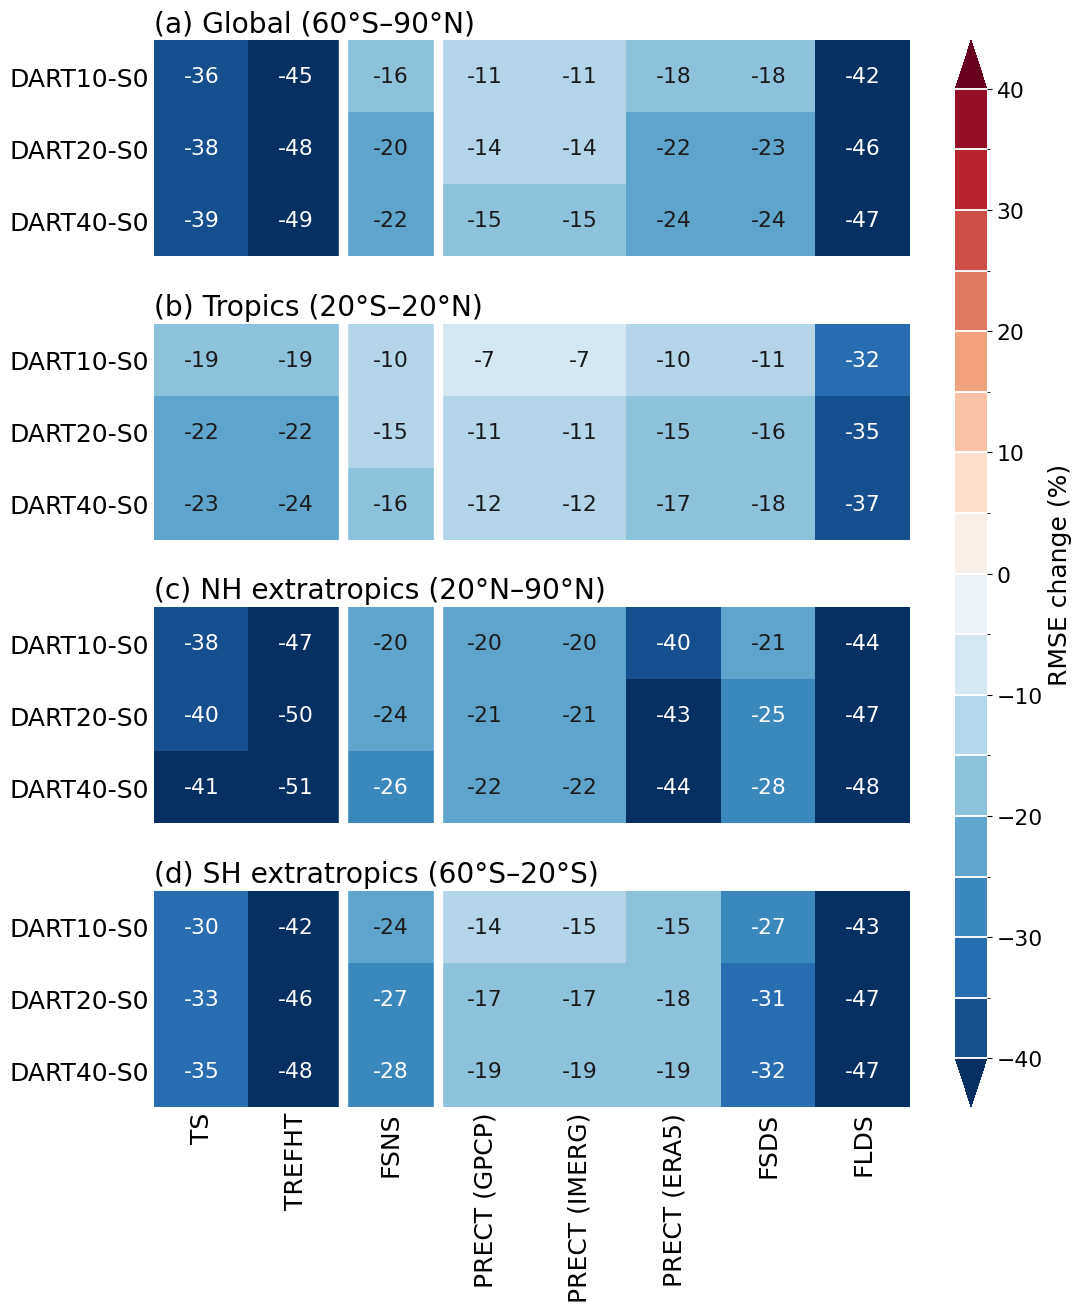

In [5]:
fig = plot_change_heatmap(
    table, variable_order=[r.name for r in rows], region_order=region_order, region_bounds=region_bounds,
    experiment_order=["DART10-S0", "DART20-S0", "DART40-S0"], experiment_label=lambda r: r.test,
    limit=color_limit, fontsize=fontsize, cbar_label=f"{score.upper()} change (%)",
)
output = figure_dir / f"fig_land_scorecard_dart_vs_ctrl_S0_{score}.pdf"
fig.savefig(output, dpi=FIGURE_DPI, bbox_inches="tight")
print(f"[FIGURE] {output}")
if not show:
    plt.close(fig)